<a href="https://colab.research.google.com/github/swarnimasingh889-create/satellite-landuse-classifier/blob/main/EuroSAT_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## EuroSAT Satellite Image Classification
 “10-class land-use classification on Sentinel-2 satellite tiles using transfer learning with ResNet18. Frozen baseline vs fine-tuned comparison.”


### Setup: libraries, GPU check and dataset download


In [1]:
import torch, random, numpy as np
torch.manual_seed(42); random.seed(42); np.random.seed(42)

In [2]:
import torch, torchvision
print(torch.__version__, torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

from torchvision.datasets import EuroSAT
dataset = EuroSAT(root="data", download=True)
print(len(dataset), dataset.classes)

2.11.0+cu130 0.26.0+cu130
GPU available: True


100%|██████████| 94.3M/94.3M [00:03<00:00, 31.1MB/s]


27000 ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


### Data loading, transforms and augmentation
Augmentation means randomly altering training images each epoch (flips, rotations), so the model can’t memorise exact pixels. That shrinks the gap between train and validation accuracy. The choice of augmentations should come from the data so we are choosing flips and rotation because a satellite image has no “correct up”, so flips and rotations are valid.

In [3]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import EuroSAT


mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(90),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


N = 27000
g = torch.Generator().manual_seed(42)
perm = torch.randperm(N, generator=g).tolist()
n_train, n_val = int(0.70 * N), int(0.15 * N)
train_idx = perm[:n_train]
val_idx   = perm[n_train:n_train + n_val]
test_idx  = perm[n_train + n_val:]

train_ds = Subset(EuroSAT("data", transform=train_tf), train_idx)
val_ds   = Subset(EuroSAT("data", transform=eval_tf),  val_idx)
test_ds  = Subset(EuroSAT("data", transform=eval_tf),  test_idx)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=2)

print(len(train_ds), len(val_ds), len(test_ds))
images, labels = next(iter(train_loader))
print(images.shape, labels[:10])

18900 4050 4050
torch.Size([64, 3, 224, 224]) tensor([1, 8, 5, 3, 3, 1, 8, 8, 1, 9])


### Displaying images using matplotlib

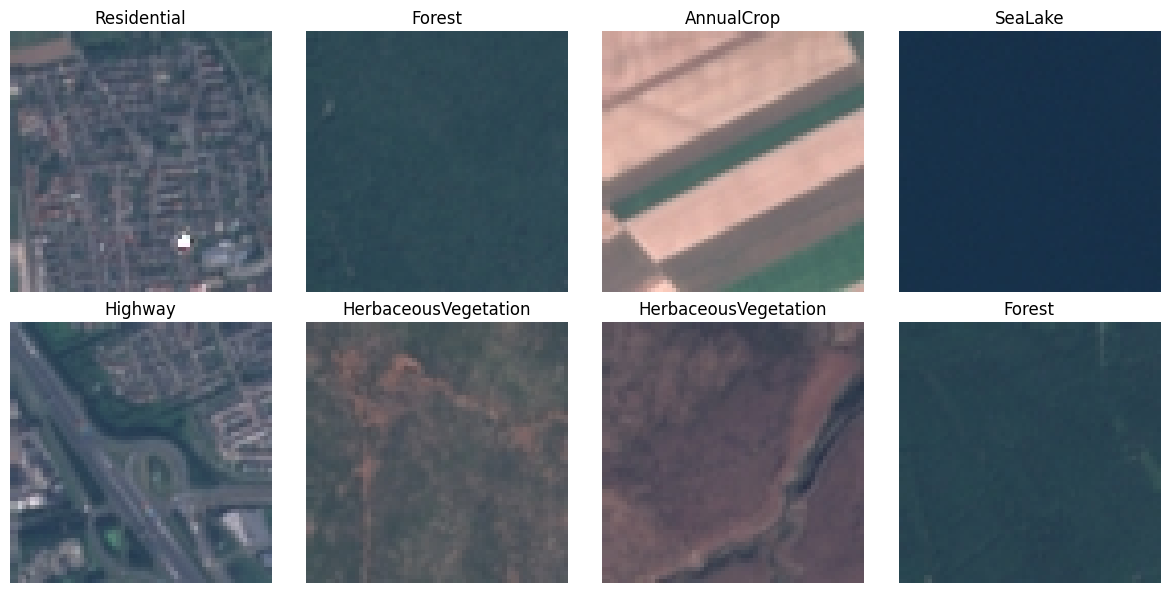

In [4]:
import matplotlib.pyplot as plt
import random

raw = EuroSAT("data")
classes = raw.classes

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    i = random.randrange(len(raw))
    img, label = raw[i]
    ax.imshow(img)
    ax.set_title(classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

### Building the baseline using pretrained ResNet18 with a new final layer

In [5]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)


for param in model.parameters():
    param.requires_grad = False

# Replace the final layer: 512 features in, 10 classes out
model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]


Trainable: 5,130 / 11,181,642


### Training loop

In [6]:
import time, copy

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            count += images.size(0)
    return total_loss / count, correct / count

EPOCHS = 5
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, best_weights = 0.0, None

for epoch in range(EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
        history[k].append(v)
    if va_acc > best_acc:
        best_acc, best_weights = va_acc, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
          f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}s")

model.load_state_dict(best_weights)
torch.save(best_weights, "resnet18_baseline.pt")
print("Best val acc:", best_acc)

Epoch 1/5 | train loss 0.866 acc 0.754 | val loss 0.688 acc 0.781 | 54s
Epoch 2/5 | train loss 0.459 acc 0.860 | val loss 0.525 acc 0.824 | 50s
Epoch 3/5 | train loss 0.396 acc 0.875 | val loss 0.448 acc 0.848 | 49s
Epoch 4/5 | train loss 0.367 acc 0.877 | val loss 0.421 acc 0.860 | 51s
Epoch 5/5 | train loss 0.340 acc 0.886 | val loss 0.452 acc 0.845 | 51s
Best val acc: 0.86


### Evaluating (confusion matrix, per-class metrics)

                      precision    recall  f1-score   support

          AnnualCrop      0.924     0.856     0.889       466
              Forest      0.946     0.935     0.940       431
HerbaceousVegetation      0.937     0.670     0.781       445
             Highway      0.795     0.795     0.795       381
          Industrial      0.854     0.963     0.905       352
             Pasture      0.739     0.955     0.833       309
       PermanentCrop      0.770     0.838     0.802       388
         Residential      0.909     0.943     0.925       454
               River      0.754     0.819     0.785       382
             SeaLake      0.977     0.860     0.915       442

            accuracy                          0.860      4050
           macro avg      0.861     0.863     0.857      4050
        weighted avg      0.869     0.860     0.860      4050



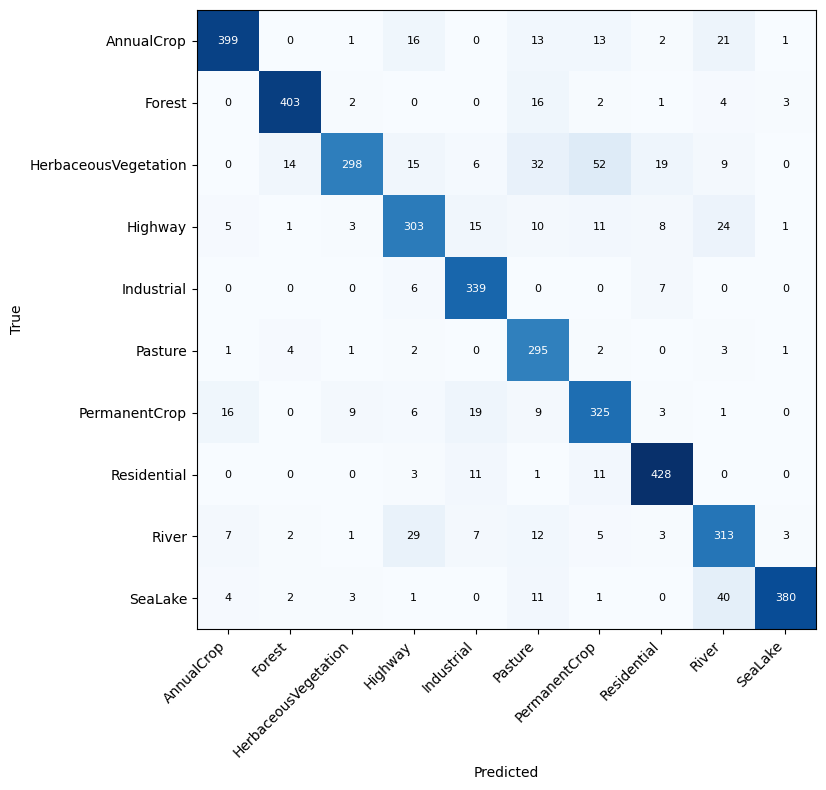

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

def get_predictions(loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_preds.extend(outputs.argmax(1).cpu().tolist())
            all_labels.extend(labels.tolist())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(val_loader)
classes = EuroSAT("data").classes

print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9,8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.tight_layout()
plt.savefig("confusion_matrix_baseline.png", dpi=150)
plt.show()

### Fine-tuning layer4 (the last residual block)
We are using a much lower learning rate for pretrained layers because they already hold useful knowledge, so we are nudging them gently (1e-4).

In [8]:
model.load_state_dict(torch.load("resnet18_baseline.pt"))

for p in model.layer4.parameters():
    p.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable: {trainable:,}")

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
])

EPOCHS = 5
history_ft = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, best_weights = 0.0, None

for epoch in range(EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history_ft, [tr_loss, tr_acc, va_loss, va_acc]):
        history_ft[k].append(v)
    if va_acc > best_acc:
        best_acc, best_weights = va_acc, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
          f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}s")

model.load_state_dict(best_weights)
torch.save(best_weights, "resnet18_finetuned.pt")
print("Best val acc:", best_acc)

Trainable: 8,398,858
Epoch 1/5 | train loss 0.239 acc 0.922 | val loss 0.195 acc 0.938 | 54s
Epoch 2/5 | train loss 0.159 acc 0.948 | val loss 0.161 acc 0.952 | 53s
Epoch 3/5 | train loss 0.135 acc 0.955 | val loss 0.115 acc 0.962 | 54s
Epoch 4/5 | train loss 0.108 acc 0.963 | val loss 0.112 acc 0.967 | 54s
Epoch 5/5 | train loss 0.096 acc 0.968 | val loss 0.135 acc 0.962 | 52s
Best val acc: 0.9669135802469135


### Evaluating the fine-tuned model

                      precision    recall  f1-score   support

          AnnualCrop      0.982     0.938     0.959       466
              Forest      0.984     0.993     0.988       431
HerbaceousVegetation      0.948     0.944     0.946       445
             Highway      0.953     0.963     0.958       381
          Industrial      0.946     0.989     0.967       352
             Pasture      0.944     0.977     0.960       309
       PermanentCrop      0.967     0.905     0.935       388
         Residential      0.983     0.998     0.990       454
               River      0.959     0.969     0.964       382
             SeaLake      0.991     0.995     0.993       442

            accuracy                          0.967      4050
           macro avg      0.966     0.967     0.966      4050
        weighted avg      0.967     0.967     0.967      4050



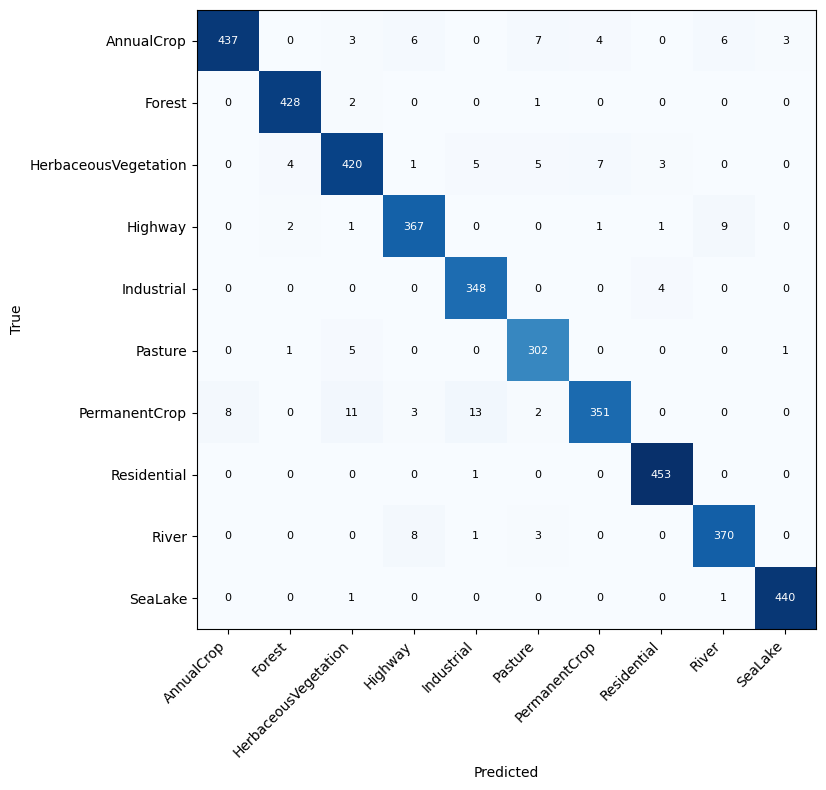

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

def get_predictions(loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_preds.extend(outputs.argmax(1).cpu().tolist())
            all_labels.extend(labels.tolist())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(val_loader)
classes = EuroSAT("data").classes

print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9,8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.tight_layout()
plt.savefig("confusion_matrix_finetuned.png", dpi=150)
plt.show()

### Error analysis

134 wrong out of 4050


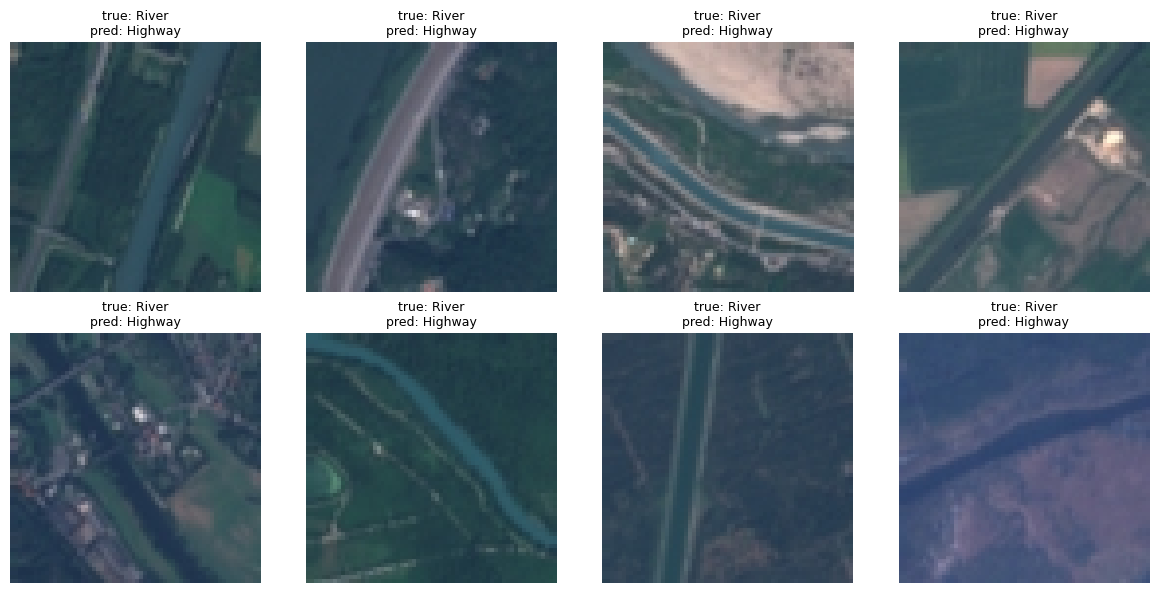

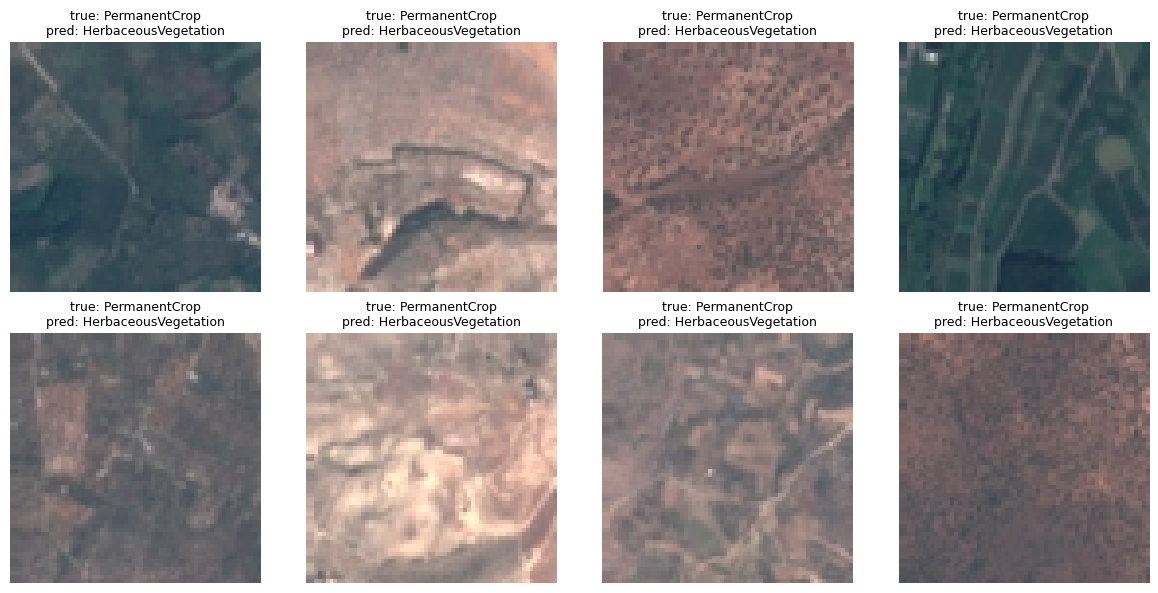

In [10]:
import random
raw = EuroSAT("data")
classes = raw.classes

y_true, y_pred = get_predictions(val_loader)
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} wrong out of {len(y_true)}")

def show_errors(true_name, pred_name, n=8):
    ti, pi = classes.index(true_name), classes.index(pred_name)
    hits = [k for k in wrong if y_true[k] == ti and y_pred[k] == pi]
    picks = random.sample(hits, min(n, len(hits)))
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, k in zip(axes.flat, picks):
        ax.imshow(raw[val_idx[k]][0])
        ax.set_title(f"true: {true_name}\npred: {pred_name}", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()

show_errors("River", "Highway")
show_errors("PermanentCrop", "HerbaceousVegetation")

### Final evaluation on the held-out test set

In [11]:
model.load_state_dict(torch.load("resnet18_finetuned.pt"))
y_true_t, y_pred_t = get_predictions(test_loader)
test_acc = (y_true_t == y_pred_t).mean()
print(f"TEST accuracy: {test_acc:.4f}")
print(classification_report(y_true_t, y_pred_t, target_names=classes, digits=3))

TEST accuracy: 0.9617
                      precision    recall  f1-score   support

          AnnualCrop      0.969     0.917     0.942       472
              Forest      0.973     0.991     0.982       442
HerbaceousVegetation      0.961     0.961     0.961       458
             Highway      0.954     0.951     0.953       391
          Industrial      0.944     0.987     0.965       378
             Pasture      0.921     0.973     0.946       299
       PermanentCrop      0.960     0.892     0.925       379
         Residential      0.987     0.989     0.988       450
               River      0.953     0.968     0.960       375
             SeaLake      0.980     0.990     0.985       406

            accuracy                          0.962      4050
           macro avg      0.960     0.962     0.961      4050
        weighted avg      0.962     0.962     0.962      4050



### Baseline model evaluated on the same test set, for a fair comparison

In [12]:
model.load_state_dict(torch.load("resnet18_baseline.pt"))
yt, yp = get_predictions(test_loader)
print("Baseline TEST accuracy:", (yt == yp).mean())

Baseline TEST accuracy: 0.8654320987654321


### Extra experiment: unfreezing layer3 (validation only)

In [13]:
model.load_state_dict(torch.load("resnet18_finetuned.pt"))
for p in model.layer3.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam([
    {"params": model.layer3.parameters(), "lr": 5e-5},
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-4},
])

best_acc, best_weights = 0.0, None
for epoch in range(3):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    if va_acc > best_acc:
        best_acc, best_weights = va_acc, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1} | train acc {tr_acc:.3f} | val acc {va_acc:.3f}")

torch.save(best_weights, "resnet18_layer3.pt")
print("Best val acc:", best_acc)

Epoch 1 | train acc 0.963 | val acc 0.963
Epoch 2 | train acc 0.969 | val acc 0.973
Epoch 3 | train acc 0.973 | val acc 0.968
Best val acc: 0.9733333333333334
